# Week 15 — Forward Diffusion on MNIST

**Mode: tutorial with experiments · Days 4–6 · CPU**

**Status:** Week 15 completed on 2026-11-05 at the learner's request after the final discussion. The Day 6 consolidation records that completion decision.

**Companion:** [the forward-process note and your Day 3 derivation](../notes/w15_forward_process_discrete.md#day-3--deriving-the-forward-distributions).

**Workflow:** Work in **w15_forward_diffusion_mnist_solved.ipynb** and keep
the unsolved file as the exercise baseline. Completed solutions and outputs
are retained in the working copy. Days 4–5 exercises appear in both
files; the completed answers and Day 6 discussion are retained here.

## Learning Goals

Turn your derivation into a small numerical experiment:

1. Construct cumulative coefficients with an explicit clean-input boundary.
2. Implement a single Gaussian step and direct noising from a clean image.
3. Interpret coefficient curves and image grids using the same clean digits.

You need NumPy, plotting basics, and the conditional mean/covariance result
from Days 1–3. Data loading, plotting, and deterministic checks are provided.
Day 4 has three implementation exercises; Day 5 adds **TODO 4 and TODO 5**. An unfinished exercise raises
a named error when its check cell first calls it.

**Day 4 time budget:** about 60 minutes, including discussion: roughly 10 for setup,
25 for the three exercises, 15 for plots, and 10 for interpretation.
If a step takes longer, bring the attempt for review.

**Day 5 is appended below Day 4 Wrap-up.** It has two new exercises (TODO 4 and TODO 5). In the working copy, Day 4 is complete and approved; rerun its completed code after a kernel restart, then continue at the Day 5 heading.

## Outline

1. Setup: cached MNIST and normalization.
2. Step 1: a linear schedule and one-step corruption.
3. Step 2: direct sampling, boundary checks, and two image grids.
4. Exercise: explain three observations.
5. Wrap-up: the Day 4 stopping point and Day 5 handoff.

Read or reread the schedule and forward-sampling code in
[Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion#defining-the-forward-diffusion-process)
as a reference when needed. Our implementations are small NumPy versions of
the equations you derived; this notebook uses the existing project dependencies.

6. Day 5: linear/cosine comparison, fixed-input Monte Carlo checks, and discussion observations.
7. Day 6: whole-process explanation, evidence discussion, learner questions, and Week 15 closeout.


---
## Setup

Run from the repository root or the notebooks directory using the project's
Python environment. All generated files stay under the ignored scratch directory.
No GPU is needed.

In [1]:
from pathlib import Path
import gzip
import hashlib
import os
import struct
import urllib.request

import numpy as np

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").exists() and (p / "notebooks").is_dir()
)
CACHE = ROOT / "scratch" / "w15_forward_diffusion"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = CACHE / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
import matplotlib.pyplot as plt

SEED = 15
rng = np.random.default_rng(SEED)
config = {
    "seed": SEED,
    "T": 1000,
    "beta_start": 1e-4,
    "beta_end": 0.02,
    "digits": (0, 1, 4, 7),
    "display_times": (0, 1, 50, 100, 250, 500, 1000),
    "normalization": "uint8 / 127.5 - 1",
}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
assert config["T"] >= max(config["display_times"])
assert 0 < config["beta_start"] <= config["beta_end"] < 1
print(f"NumPy on CPU | seed={SEED} | T={config['T']} | outputs: {FIGURE_DIR}")

NumPy on CPU | seed=15 | T=1000 | outputs: /Users/juanpineros/juancopi81/diffusion-research-curriculum/scratch/w15_forward_diffusion/figures


### Provided infrastructure: MNIST and a fixed set of clean inputs

This reuses the checksum-verified IDX/gzip loading approach from the
[Week 11 VAE notebook](w11_minimal_vae_mnist.ipynb). It first looks for the
two existing test-set files under scratch/w11_vae/mnist; a missing file is
downloaded from the same [MNIST mirror](https://ossci-datasets.s3.amazonaws.com/mnist/)
into this week's ignored cache. The cached files are checked before decoding.

The arrays use **(batch, channel, height, width)** order. We map byte pixels
to $[-1,1]$, so the clean image scale is explicit relative to unit Gaussian
noise. This centers the available pixel range, without asserting a zero
dataset mean or unit dataset variance.

In [2]:
MNIST_URL = "https://ossci-datasets.s3.amazonaws.com/mnist/"
RESOURCES = {
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def read_mnist(filename: str) -> np.ndarray:
    """Load a checksum-verified MNIST test file, reusing Week 11's cache."""
    previous = ROOT / "scratch" / "w11_vae" / "mnist" / filename
    folder = CACHE / "mnist"
    folder.mkdir(exist_ok=True)
    target = previous if previous.exists() else folder / filename
    if not target.exists():
        print(f"Downloading {filename}")
        with urllib.request.urlopen(MNIST_URL + filename, timeout=30) as response:
            payload = response.read()
        if hashlib.md5(payload).hexdigest() != RESOURCES[filename]:
            raise ValueError(f"Checksum mismatch: {filename}")
        target.write_bytes(payload)
    payload = target.read_bytes()
    if hashlib.md5(payload).hexdigest() != RESOURCES[filename]:
        raise ValueError(f"Corrupt cache file: {target}")
    raw = gzip.decompress(payload)
    magic, count = struct.unpack(">II", raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack(">II", raw[8:16])
        assert (rows, cols) == (28, 28)
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols)
    assert magic == 2049, f"Unexpected IDX magic: {magic}"
    return np.frombuffer(raw, dtype=np.uint8, offset=8).reshape(count)


raw_images = read_mnist("t10k-images-idx3-ubyte.gz")
raw_labels = read_mnist("t10k-labels-idx1-ubyte.gz")
assert raw_images.shape == (len(raw_labels), 28, 28)
selection_rng = np.random.default_rng(SEED)
indices = np.array([
    selection_rng.choice(np.flatnonzero(raw_labels == digit))
    for digit in config["digits"]
])
labels = raw_labels[indices]
x0 = raw_images[indices].astype(np.float64)[:, None, :, :] / 127.5 - 1.0
assert x0.shape == (len(config["digits"]), 1, 28, 28)
assert -1 <= x0.min() <= x0.max() <= 1
assert np.array_equal(labels, config["digits"])
print(f"Clean batch: {x0.shape} | raw normalized range: [{x0.min():.1f}, {x0.max():.1f}]")

Clean batch: (4, 1, 28, 28) | raw normalized range: [-1.0, 1.0]


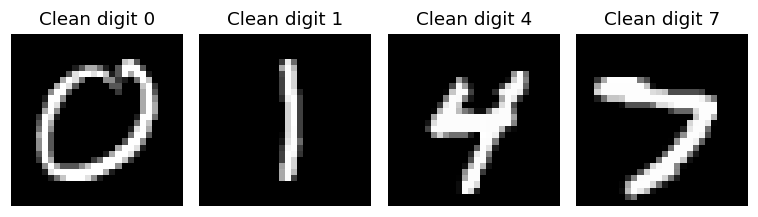

In [3]:
fig, axes = plt.subplots(1, len(x0), figsize=(7, 2))
for ax, image, label in zip(axes, x0, labels):
    ax.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"Clean digit {label}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_clean_inputs.png", bbox_inches="tight")
plt.show()

---
## Step 1: Minimal Example

### Timestep convention

The mathematical times are $t=0,\ldots,T$:

- $t=0$ is the clean input.
- Entry $t$ stores $\beta_t$ for the step from $t-1$ to $t$.
- A leading placeholder $\beta_0=0$ makes every table have length $T+1$.
  It is an indexing convention; actual noising steps still have $0<\beta_t<1$.

Consequently $\alpha_0=\bar\alpha_0=1$. We retain this entry explicitly
instead of treating array index zero as the first corrupted image.

In [4]:
# Provided linear schedule; all arrays include the clean-input entry.
betas = np.concatenate((
    np.array([0.0]),
    np.linspace(config["beta_start"], config["beta_end"], config["T"]),
))
assert betas.shape == (config["T"] + 1,)
assert betas[0] == 0 and np.all((betas[1:] > 0) & (betas[1:] < 1))

### TODO 1 of 3 — Accumulate the schedule (about 5 minutes)

Implement the two definitions you already used:

$$
\alpha_t=1-\beta_t,\qquad
\bar\alpha_t=\prod_{s=1}^{t}\alpha_s.
$$

Fill the two assignments in the function below. NumPy's **cumprod**
computes cumulative products. Include the leading clean-input entry.

In [5]:
def cumulative_coefficients(betas: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return alpha and alpha_bar arrays, including the clean time t=0."""
    # TODO 1: replace the two None values using the definitions above.
    alphas = (1 - betas)
    alpha_bar = np.cumprod(alphas)
    if alphas is None or alpha_bar is None:
        raise NotImplementedError("Complete TODO 1: schedule coefficients.")
    return alphas, alpha_bar

In [6]:
# CHECKPOINT: a short schedule has a known two-step cumulative product.
probe_betas = np.array([0.0, 0.04, 0.25])
probe_alphas, probe_alpha_bar = cumulative_coefficients(probe_betas)
np.testing.assert_allclose(probe_alphas, [1.0, 0.96, 0.75])
np.testing.assert_allclose(probe_alpha_bar, [1.0, 0.96, 0.72])

alphas, alpha_bar = cumulative_coefficients(betas)
assert alphas.shape == alpha_bar.shape == betas.shape
assert alpha_bar[0] == 1.0
assert np.all(np.isfinite(alpha_bar)) and np.all(alpha_bar > 0)
assert np.all(np.diff(alpha_bar) <= 0)
np.testing.assert_allclose(alpha_bar[1], 1 - betas[1])
print("Schedule checks passed: t=0, t=1, and accumulated two-step values.")

Schedule checks passed: t=0, t=1, and accumulated two-step values.


### Predict, then inspect the curves

Before running: sketch the two amplitudes and the conditional noise variance.
Where should the amplitude curves cross vertically? Which curve represents
the covariance coefficient from your proof?

The dashed horizontal reference marks $\bar\alpha_t=1/2$ in the right plot;
the corresponding amplitudes in the left plot are $1/\sqrt{2}$.

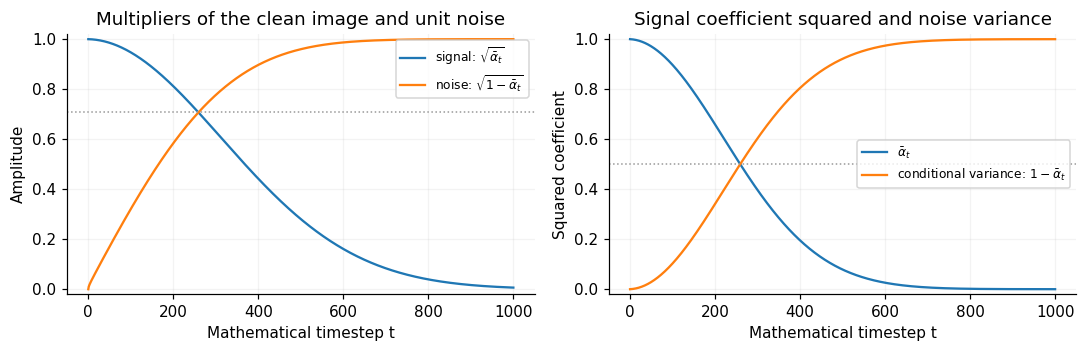

In [7]:
times = np.arange(config["T"] + 1)
signal_amplitude = np.sqrt(alpha_bar)
noise_amplitude = np.sqrt(1.0 - alpha_bar)
conditional_variance = 1.0 - alpha_bar
np.testing.assert_allclose(signal_amplitude**2 + noise_amplitude**2, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(times, signal_amplitude, label=r"signal: $\sqrt{\bar\alpha_t}$")
axes[0].plot(times, noise_amplitude, label=r"noise: $\sqrt{1-\bar\alpha_t}$")
axes[0].axhline(1 / np.sqrt(2), color="0.6", ls=":", lw=1)
axes[0].set(xlabel="Mathematical timestep t", ylabel="Amplitude",
            title="Multipliers of the clean image and unit noise")
axes[1].plot(times, alpha_bar, label=r"$\bar\alpha_t$")
axes[1].plot(times, conditional_variance, label=r"conditional variance: $1-\bar\alpha_t$")
axes[1].axhline(0.5, color="0.6", ls=":", lw=1)
axes[1].set(xlabel="Mathematical timestep t", ylabel="Squared coefficient",
            title="Signal coefficient squared and noise variance")
for ax in axes:
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_schedule.png", bbox_inches="tight")
plt.show()

### TODO 2 of 3 — One Gaussian step (about 5–10 minutes)

Implement the same transition as in your handwritten expansion:

$$
x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t.
$$

The helper receives the noise explicitly. This lets you test its arithmetic
with a fixed noise array; the sequential driver below will supply fresh
Gaussian draws at each step. Fill the single assignment.

In [8]:
def q_step(
    x_previous: np.ndarray, t: int, betas: np.ndarray, noise: np.ndarray
) -> np.ndarray:
    """Apply one Gaussian transition from mathematical time t-1 to t."""
    assert 1 <= t < len(betas), "q_step starts at t=1; t=0 is already clean."
    assert x_previous.shape == noise.shape
    beta_t = betas[t]
    # TODO 2: combine the previous state and supplied noise.
    x_t = (np.sqrt(1 - beta_t) * x_previous) + (np.sqrt(beta_t) * noise)
    if x_t is None:
        raise NotImplementedError("Complete TODO 2: the one-step equation.")
    return x_t

In [9]:
# CHECKPOINT: reproduce Day 1's scalar calculation and a second coordinate.
probe_x = np.array([[2.0, -1.0]])
probe_noise = np.array([[0.5, -2.0]])
expected_step = np.array([[2.0595917942265424, -1.3797958971132713]])
probe_step = q_step(probe_x, 1, probe_betas, probe_noise)
assert probe_step.shape == probe_x.shape
np.testing.assert_allclose(probe_step, expected_step, atol=1e-12)
print("One-step check passed: signal scaling and noise standard deviation.")

One-step check passed: signal scaling and noise standard deviation.


---
## Step 2: Interpret the Result

### Provided helper: broadcast a coefficient over images

A batch can share one timestep or have one timestep per image.
The helper turns selected table entries into shapes that broadcast over
the image coordinates. This is provided so the exercise stays focused on
the noising equation.

In [10]:
def coefficient_at(
    table: np.ndarray, t: int | np.ndarray, batch: np.ndarray
) -> np.ndarray:
    """Select a shared or per-image coefficient with broadcastable shape."""
    t_array = np.asarray(t)
    assert np.issubdtype(t_array.dtype, np.integer), "Use integer timesteps."
    assert np.all((t_array >= 0) & (t_array < len(table)))
    if t_array.ndim == 0:
        return np.asarray(table[int(t_array)])
    assert t_array.shape == (batch.shape[0],), "Supply one time per image."
    return table[t_array].reshape((batch.shape[0],) + (1,) * (batch.ndim - 1))


assert coefficient_at(np.ones(3), 0, x0).shape == ()
assert coefficient_at(np.ones(3), np.zeros(len(x0), dtype=int), x0).shape == (4, 1, 1, 1)

### TODO 3 of 3 — Direct sampling (about 5–10 minutes)

Implement the closed form you derived:

$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon.
$$

Fill the assignment using **alpha_bar_t**, the clean input, and the supplied
noise. Keep the raw result: Gaussian corruption is allowed to leave
$[-1,1]$. Display clipping is handled separately.

In [11]:
def q_sample(
    x0: np.ndarray, t: int | np.ndarray, alpha_bar: np.ndarray, noise: np.ndarray
) -> np.ndarray:
    """Sample the conditional marginal at time t using supplied unit noise."""
    assert x0.shape == noise.shape
    alpha_bar_t = coefficient_at(alpha_bar, t, x0)
    # TODO 3: combine the clean input and supplied noise.
    x_t = np.sqrt(alpha_bar_t) * x0 + np.sqrt(1 - alpha_bar_t) * noise
    if x_t is None:
        raise NotImplementedError("Complete TODO 3: the direct-sampling equation.")
    return x_t

In [12]:
# CHECKPOINT: t=0, t=1, the two-step result, shapes, and raw values.
check_noise = np.random.default_rng(SEED + 1).standard_normal(x0.shape)
np.testing.assert_array_equal(q_sample(x0, 0, alpha_bar, check_noise), x0)
np.testing.assert_allclose(
    q_sample(x0, 1, alpha_bar, check_noise),
    q_step(x0, 1, betas, check_noise),
)
expected_two_step = (
    np.sqrt(0.72) * probe_x + np.sqrt(0.28) * probe_noise
)
np.testing.assert_allclose(
    q_sample(probe_x, 2, probe_alpha_bar, probe_noise), expected_two_step,
)
batch_times = np.array([0, 1, 250, config["T"]])
mixed_times = q_sample(x0, batch_times, alpha_bar, check_noise)
assert mixed_times.shape == x0.shape and np.all(np.isfinite(mixed_times))
for row, t in enumerate(batch_times):
    np.testing.assert_allclose(
        mixed_times[row:row + 1],
        q_sample(x0[row:row + 1], int(t), alpha_bar, check_noise[row:row + 1]),
    )
# A deliberately large supplied noise value catches clipping inside q_sample.
assert q_sample(x0, config["T"], alpha_bar, np.full_like(x0, 3.0)).max() > 1.0
print("Direct-sampling checks passed: boundaries, two-step formula, broadcasting, raw range.")

Direct-sampling checks passed: boundaries, two-step formula, broadcasting, raw range.


### Provided plotting: show the same images across time

Each row keeps the same clean input; columns show selected mathematical
times. The display uses a fixed gray scale and clips a copy for viewing.
The saved arrays and all calculations retain the raw unbounded samples.

In [13]:
def show_snapshots(
    snapshots: dict[int, np.ndarray], title: str, filename: str
) -> None:
    """Show fixed-scale image snapshots and save a small figure."""
    display_times = list(config["display_times"])
    fig, axes = plt.subplots(
        len(x0), len(display_times), figsize=(11, 6), squeeze=False,
    )
    for row, label in enumerate(labels):
        for col, t in enumerate(display_times):
            ax = axes[row, col]
            ax.imshow(np.clip(snapshots[t][row, 0], -1, 1),
                      cmap="gray", vmin=-1, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(f"t={t}")
            if col == 0:
                ax.set_ylabel(f"Digit {label}")
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()

### Sequential trajectory

Before running, predict which displayed columns will still retain recognizable
structure. The driver uses your one-step function, with a fresh noise array
for every step. Resetting the local generator makes this cell reproducible.

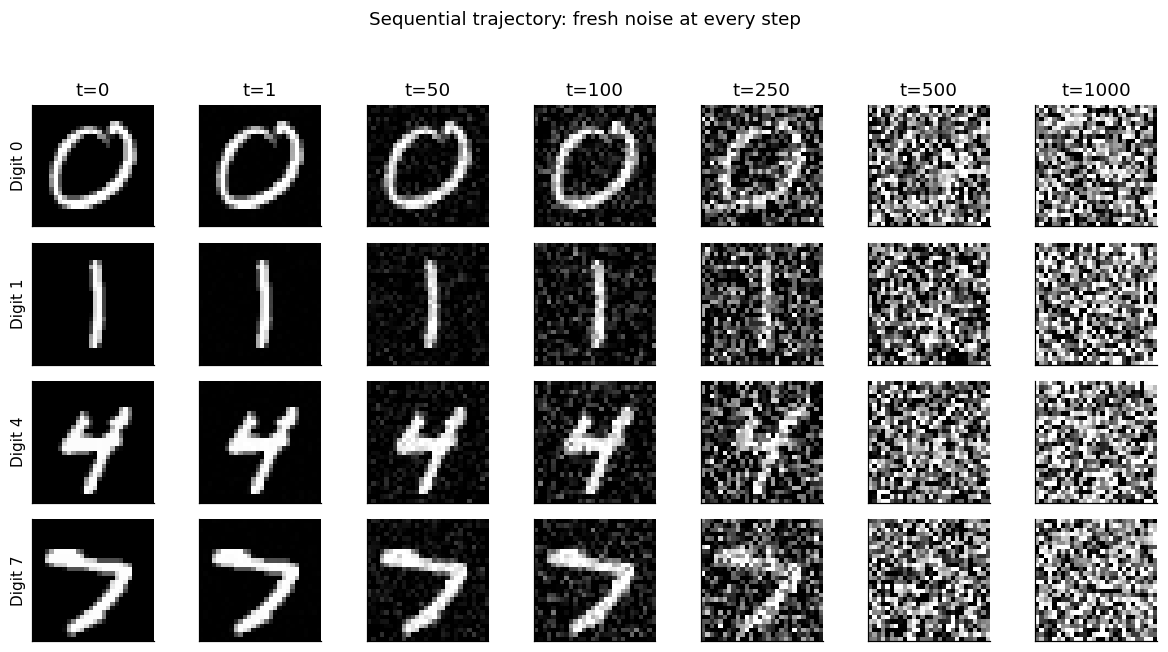

In [14]:
sequential_rng = np.random.default_rng(SEED + 10)
x_previous = x0.copy()
sequential_snapshots = {0: x0.copy()}
for t in range(1, config["T"] + 1):
    fresh_noise = sequential_rng.standard_normal(x0.shape)
    x_previous = q_step(x_previous, t, betas, fresh_noise)
    if t in config["display_times"]:
        sequential_snapshots[t] = x_previous.copy()

assert set(sequential_snapshots) == set(config["display_times"])
assert all(x.shape == x0.shape and np.all(np.isfinite(x))
           for x in sequential_snapshots.values())
np.testing.assert_array_equal(sequential_snapshots[0], x0)
show_snapshots(
    sequential_snapshots, "Sequential trajectory: fresh noise at every step",
    "day4_sequential.png",
)

### Direct conditional samples

The next grid uses your direct formula with fresh noise for each displayed
time. These columns are separate samples from $q(x_t\mid x_0)$; they do not
constitute a sequential Markov trajectory.

You should expect agreement in the conditional law at each time, without
pixel-for-pixel agreement with the independently generated sequential grid.
The pictures illustrate corruption; Day 5 will check moments with repeated
draws for fixed clean inputs.

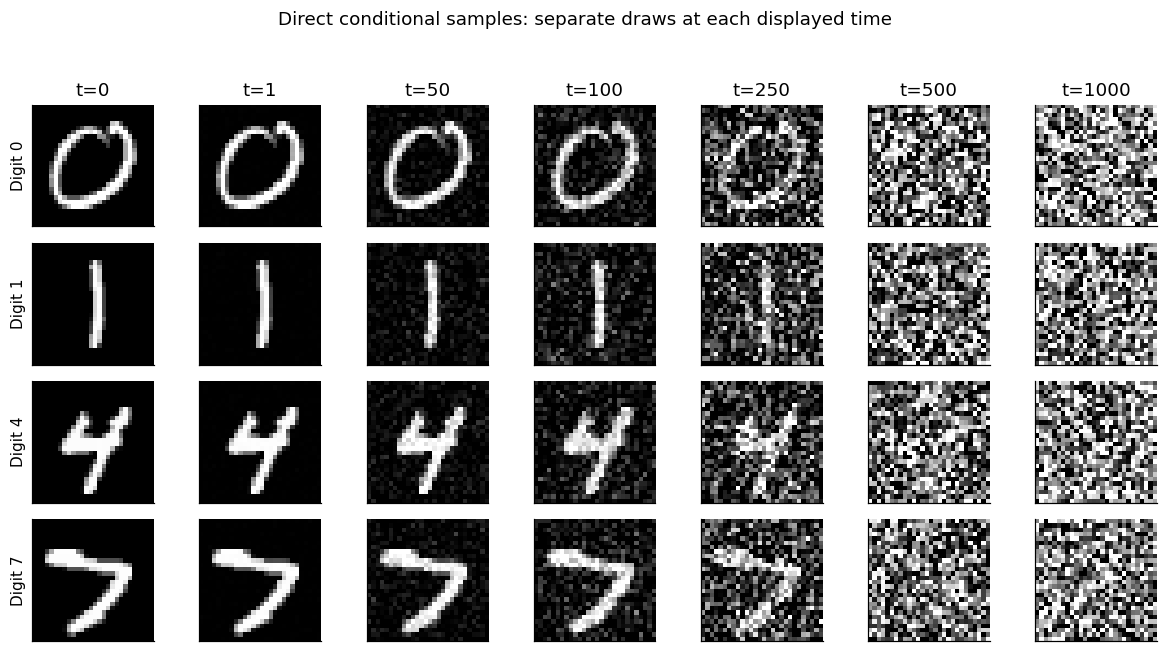

Raw terminal range — sequential: [-3.32, 3.70]
Raw terminal range — direct: [-3.45, 3.76]


In [15]:
direct_rng = np.random.default_rng(SEED + 20)
direct_snapshots = {0: x0.copy()}
for t in config["display_times"][1:]:
    fresh_noise = direct_rng.standard_normal(x0.shape)
    direct_snapshots[t] = q_sample(x0, t, alpha_bar, fresh_noise)

assert set(direct_snapshots) == set(config["display_times"])
assert all(x.shape == x0.shape and np.all(np.isfinite(x))
           for x in direct_snapshots.values())
np.testing.assert_array_equal(direct_snapshots[0], x0)
show_snapshots(
    direct_snapshots, "Direct conditional samples: separate draws at each displayed time",
    "day4_direct.png",
)
print(f"Raw terminal range — sequential: [{x_previous.min():.2f}, {x_previous.max():.2f}]")
print(f"Raw terminal range — direct: [{direct_snapshots[config['T']].min():.2f}, "
      f"{direct_snapshots[config['T']].max():.2f}]")

In [16]:
# Coefficients predicted by the schedule; these are not empirical moment estimates.
print("    t   signal amplitude   noise amplitude   conditional variance")
for t in config["display_times"]:
    print(f"{t:5d}   {signal_amplitude[t]:16.6f}   "
          f"{noise_amplitude[t]:15.6f}   {conditional_variance[t]:20.6f}")
assert conditional_variance[0] == 0
print("Run settings:", config)

    t   signal amplitude   noise amplitude   conditional variance
    0           1.000000          0.000000               0.000000
    1           0.999950          0.010000               0.000100
   50           0.985401          0.170248               0.028984
  100           0.947110          0.320908               0.102982
  250           0.723937          0.689866               0.475915
  500           0.280334          0.959902               0.921413
 1000           0.006353          0.999980               0.999960
Run settings: {'seed': 15, 'T': 1000, 'beta_start': 0.0001, 'beta_end': 0.02, 'digits': (0, 1, 4, 7), 'display_times': (0, 1, 50, 100, 250, 500, 1000), 'normalization': 'uint8 / 127.5 - 1'}


---
## Exercise

Write one or two sentences per item in your working copy, then bring these
answers and any failed checkpoint to our discussion.

1. **Boundary and scale:** What does the $t=0$ result show? Why can the
   raw noisy values extend beyond the normalized image range?
2. **Curves and images:** Pick one intermediate time. Use the coefficients
   to explain what you observe in a digit, distinguishing noise amplitude
   from conditional variance.
3. **Two constructions:** What agrees between sequential and direct
   sampling? What evidence would be needed to check that agreement beyond
   comparing four pictures?

### Your observations — consolidated after discussion

**Discussion and final learner read-through completed on 2026-11-03.**

1. **Boundary and scale:** At $t=0$, I get the clean image $x_0$ because the signal amplitude is one and the noise amplitude is zero. Each standard-normal noise coordinate has about a 68% chance of falling within $[-1,1]$, but values outside that range are possible. Adding a scaled noise draw to a scaled clean pixel can therefore take the raw result outside the normalized image range; the plotting code clips only for display.

2. **Curves and images:** At $t=100$, I can still recognize the four digits despite visible noise. The direct formula is approximately $x_{100}=0.9471\,x_0+0.3209\,\epsilon$: every clean pixel value is multiplied by $0.9471$, and each corresponding noise draw is multiplied by $0.3209$. A noise draw of $0.1$ contributes about $0.03209$, and signed noise can raise or lower the pixel value. The conditional variance per coordinate is $0.3209^2\approx0.10298$; this is not a percentage of the image. Direct sampling starts from $x_0$; the single-step update to time 100 starts from $x_{99}$ and uses $\beta_{100}$.

3. **Two constructions:** The sequential and direct grids show similar qualitative corruption and both recover the clean inputs at $t=0$. For the same fixed clean input and timestep, both sample from the conditional distribution derived on Day 3, so their conditional means and covariances agree; individual draws need not match pixel by pixel. To check the implementations numerically, I would fix one clean pixel and a timestep, collect many independent samples from each method, and estimate their means and variances by Monte Carlo. My suggested 100 draws would be a starting approximation with sampling error. This numerical experiment remains for Day 5.

For that proposed check, the reference mean and variance for a fixed clean coordinate $x_{0,j}$ are

$$
\mu_{t,j}=\sqrt{\bar\alpha_t}\,x_{0,j},
\qquad
v_{t,j}=1-\bar\alpha_t.
$$

Estimate variance across the individual draws around their sample mean, while keeping the clean input and timestep fixed.

### Review notes — attempts and corrections

These observations consolidate my original answers and the subsequent discussion with Codex:

- I initially described the conditional variance near $0.103$ as roughly 10% noise and 90% image. We corrected this to distinguish amplitudes, conditional variance, and proportions of an image.
- I briefly used $x_{99}$ while describing direct sampling. I then correctly wrote the single-step update below and distinguished it from the direct formula starting at $x_0$.
- I initially suggested comparing individual pixel differences. After a prompt about fixing a clean pixel and timestep, I proposed repeated sampling and Monte Carlo moment estimates instead.

The corrected single-step update is

$$
x_{100}=\sqrt{1-\beta_{100}}\,x_{99}
+\sqrt{\beta_{100}}\,\epsilon_{100},
\qquad \epsilon_{100}\sim\mathcal N(0,I).
$$

**Added clarification from Codex:** Given a fixed $x_0$, the signal term is deterministic, so all conditional variance comes from noise. Across different clean images, the variance balance also depends on the clean-data covariance. Normalizing the pixel range to $[-1,1]$ does not impose unit data variance.

**Code verification:** All three completed implementations were reviewed and all 16 code cells passed a fresh execution on 2026-11-03. The second schedule and repeated-draw moment checks are the next experiment.

See the [full Day 4 discussion and saved figures](../notes/w15_forward_process_discrete.md#day-4--implementing-and-interpreting-forward-noising) for the evidence and review record.

---
## Wrap-up

**Status:** Day 4 completed on 2026-11-03. The learner reviewed and approved the notebook, consolidated observations, and correction record.

**Day 4 stopping point:** all three exercise checkpoints pass; you have
the coefficient plot and both image grids; normalization, seed, schedule,
timesteps, and raw-value ranges are recorded; and you can explain three
observations. Keep questions visible and stop within the session budget.
Implementation passing its checks does not by itself record learner review
or complete the whole week.

**Common pitfalls:** forgetting the square root on the noise coefficient;
using a per-step $\alpha_t$ where $\bar\alpha_t$ is needed; shifting array
indices by one; clipping the stored samples; treating direct snapshots as
a sequential trajectory.

**Optional later extension:** find the first timestep where the signal
amplitude drops below 0.1 and relate it to $\bar\alpha_t$.

**Day 5:** compare a second schedule and empirically verify the conditional
mean and covariance with repeated independent draws for fixed clean
coordinates. These tasks can extend this notebook after today's review.
The schedule convention and noising equations also carry into Week 16.

---
# Day 5 — Compare Schedules and Check Conditional Moments

**Material prepared on 2026-11-03 · experiment · about 60 minutes**

**Day 5 completed on 2026-11-04, including learner approval of the note and notebook observations.**

Day 4 is complete and approved in the working copy. Continue in that file.
After a kernel restart, run the completed Day 4 code cells to restore its
functions and data, then begin here. Its code and saved outputs are retained.

**Questions:** How do linear and cosine schedules corrupt the same clean
images? Do sequential and direct implementations reproduce the derived
conditional moments when we repeatedly sample a fixed clean input?

**Provided:** cosine schedule, matched-noise image comparison, sample
collection, diagnostic tolerances, plots, and result export. Fill only
**TODO 4 and TODO 5**, then interpret the evidence.

**Budget:** about 20 minutes for schedules and plots, 25 for moment checks,
and 15 for observations and discussion. Stop at Day 5 Wrap-up and bring any
unfinished reasoning or failed check.

## Day 5 · 1. Compare the schedules

We retain $T=1000$ and the Day 4 linear schedule. The provided cosine helper
follows the schedule code in
[Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion#defining-the-forward-diffusion-process),
checked on 2026-11-03. It specifies a desired cumulative curve from a
normalized cosine-squared function, then derives adjacent-step betas.

We record its offset $s=0.008$ and beta clipping bounds $[10^{-4},0.9999]$.
After clipping, we **recompute** the actual cumulative product from the
resulting betas. These are the coefficients the samplers really use.

Before running: predict which schedule will retain more clean structure
at an intermediate timestep. Compare the same input images with the same
noise arrays. This experiment measures corruption behavior.

In [17]:
import csv

day5_config = {
    "T": config["T"],
    "cosine_offset": 0.008,
    "cosine_beta_min": 1e-4,
    "cosine_beta_max": 0.9999,
    "n_draws": 4000,
    "mc_times": (1, 100, 500, 1000),
    "visual_seed": SEED + 30,
    "mc_seed": SEED + 50,
    "diagnostic_se_limit": 6.0,
}
assert day5_config["T"] == 1000
assert day5_config["n_draws"] >= 2
assert all(1 <= t <= config["T"] for t in day5_config["mc_times"])


def cosine_beta_schedule(n_steps: int, offset: float) -> np.ndarray:
    """Build a clipped cosine schedule with an explicit clean-input entry."""
    normalized_time = np.arange(n_steps + 1, dtype=np.float64) / n_steps
    desired = np.cos(
        (normalized_time + offset) / (1.0 + offset) * np.pi / 2
    ) ** 2
    desired = desired / desired[0]
    adjacent_betas = 1.0 - desired[1:] / desired[:-1]
    adjacent_betas = np.clip(
        adjacent_betas,
        day5_config["cosine_beta_min"], day5_config["cosine_beta_max"],
    )
    return np.concatenate(([0.0], adjacent_betas))


cosine_betas = cosine_beta_schedule(config["T"], day5_config["cosine_offset"])
_, cosine_alpha_bar = cumulative_coefficients(cosine_betas)
day5_schedules = {
    "linear": {"betas": betas.copy(), "alpha_bar": alpha_bar.copy()},
    "cosine": {"betas": cosine_betas, "alpha_bar": cosine_alpha_bar},
}
for schedule in day5_schedules.values():
    assert schedule["betas"].shape == schedule["alpha_bar"].shape == (config["T"] + 1,)
    assert schedule["betas"][0] == 0 and schedule["alpha_bar"][0] == 1
    assert np.all((schedule["betas"][1:] > 0) & (schedule["betas"][1:] < 1))
    assert np.all(np.isfinite(schedule["alpha_bar"])) and np.all(schedule["alpha_bar"] > 0)
    assert np.all(np.diff(schedule["alpha_bar"]) <= 0)
np.testing.assert_allclose(
    cosine_alpha_bar, np.cumprod(1.0 - cosine_betas),
)
assert not np.allclose(alpha_bar, cosine_alpha_bar)
print("Schedule comparison settings:", day5_config)

Schedule comparison settings: {'T': 1000, 'cosine_offset': 0.008, 'cosine_beta_min': 0.0001, 'cosine_beta_max': 0.9999, 'n_draws': 4000, 'mc_times': (1, 100, 500, 1000), 'visual_seed': 45, 'mc_seed': 65, 'diagnostic_se_limit': 6.0}


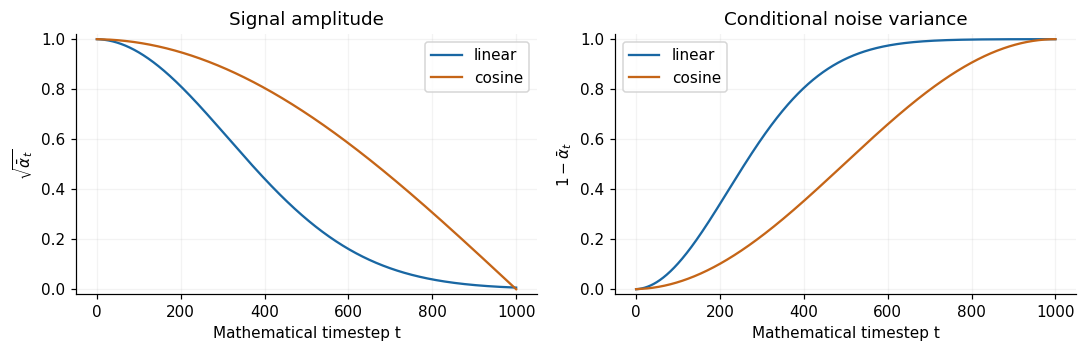

schedule     t   signal amplitude   conditional variance
linear     100           0.947110               0.102982
linear     500           0.280334               0.921413
linear    1000           0.006353               0.999960
cosine     100           0.985758               0.028281
cosine     500           0.702605               0.506346
cosine    1000           0.000016               1.000000


In [18]:
day5_colors = {"linear": "#1967a3", "cosine": "#c56517"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for name, schedule in day5_schedules.items():
    ab = schedule["alpha_bar"]
    axes[0].plot(np.arange(len(ab)), np.sqrt(ab), color=day5_colors[name], label=name)
    axes[1].plot(np.arange(len(ab)), 1.0 - ab, color=day5_colors[name], label=name)
axes[0].set(title="Signal amplitude", ylabel=r"$\sqrt{\bar\alpha_t}$")
axes[1].set(title="Conditional noise variance", ylabel=r"$1-\bar\alpha_t$")
for ax in axes:
    ax.set(xlabel="Mathematical timestep t", ylim=(-0.02, 1.02))
    ax.grid(alpha=0.15)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day5_schedule_comparison.png", bbox_inches="tight")
plt.show()

print("schedule     t   signal amplitude   conditional variance")
for name, schedule in day5_schedules.items():
    for t in (100, 500, config["T"]):
        ab = schedule["alpha_bar"][t]
        print(f"{name:8s} {t:5d} {np.sqrt(ab):18.6f} {1-ab:22.6f}")

### Provided comparison: same images and matched noise

Each displayed time has one noise array shared between the two schedules.
This controls noise realization while comparing the different coefficients.
Across times, these are direct conditional samples, not a Markov trajectory.

At the same $t$, the two schedules may have different $\bar\alpha_t$ and
therefore different conditional distributions. Sequential and direct
agreement is checked **within each schedule** below.

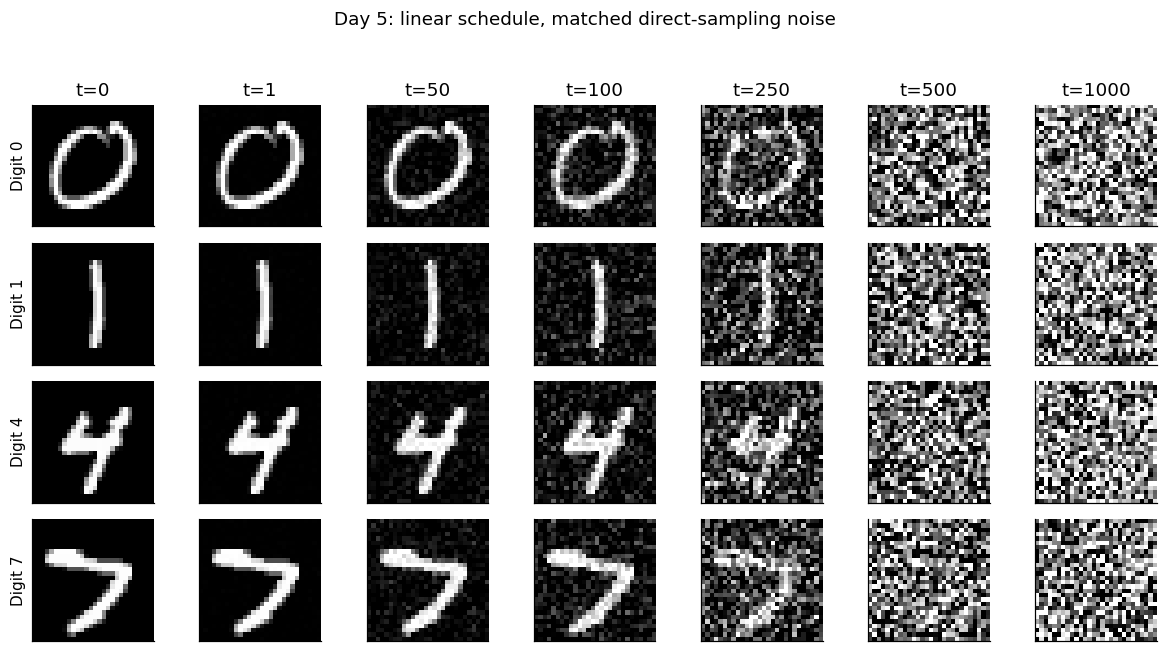

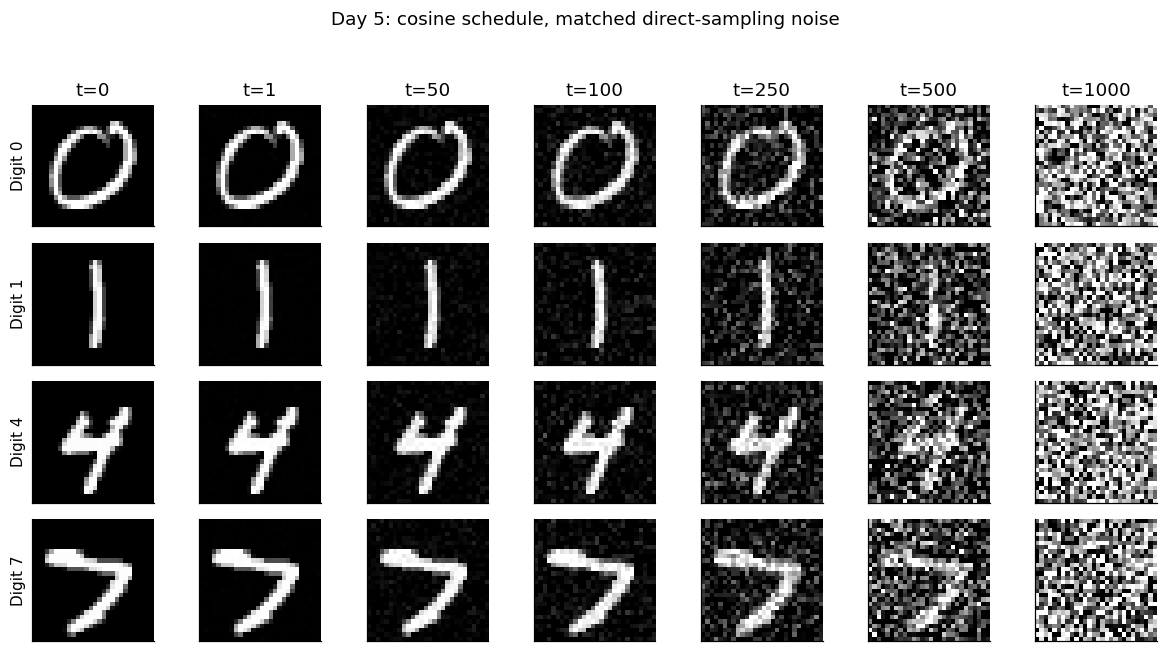

Matched comparison passed: same inputs, times, and supplied noise.


In [19]:
visual_rng = np.random.default_rng(day5_config["visual_seed"])
matched_noise = {
    t: visual_rng.standard_normal(x0.shape) for t in config["display_times"]
}
day5_images = {}
for name, schedule in day5_schedules.items():
    snapshots = {
        t: q_sample(x0, t, schedule["alpha_bar"], matched_noise[t])
        for t in config["display_times"]
    }
    np.testing.assert_array_equal(snapshots[0], x0)
    assert all(s.shape == x0.shape and np.all(np.isfinite(s)) for s in snapshots.values())
    # Recover the same supplied noise from both schedules at each positive time.
    for t in config["display_times"][1:]:
        ab = schedule["alpha_bar"][t]
        recovered = (snapshots[t] - np.sqrt(ab) * x0) / np.sqrt(1.0 - ab)
        np.testing.assert_allclose(recovered, matched_noise[t], atol=1e-12)
    day5_images[name] = snapshots
    show_snapshots(
        snapshots, f"Day 5: {name} schedule, matched direct-sampling noise",
        f"day5_{name}_matched.png",
    )
print("Matched comparison passed: same inputs, times, and supplied noise.")

## Day 5 · 2. Fix what we condition on

Choose two coordinates from the first clean image: a darkest pixel and a
brightest pixel. Their locations and clean values stay fixed throughout
the Monte Carlo experiment. The arrays will have shape **(repetitions, 2)**.

Within each column, the only source of variation is fresh Gaussian noise.
This estimates conditional moments for fixed clean values, without mixing
different pixels or different input images into the variance calculation.
The two-dimensional version also lets us inspect the predicted zero
cross-covariance.

In [20]:
fixed_image = x0[0, 0]
fixed_locations = [
    tuple(int(v) for v in np.unravel_index(np.argmin(fixed_image), fixed_image.shape)),
    tuple(int(v) for v in np.unravel_index(np.argmax(fixed_image), fixed_image.shape)),
]
fixed_point = np.array([fixed_image[location] for location in fixed_locations])
assert fixed_point.shape == (2,) and fixed_point[0] < fixed_point[1]
print(f"Fixed digit: {labels[0]}")
for location, value in zip(fixed_locations, fixed_point):
    print(f"Pixel {location}: clean value {value:.6f}")

Fixed digit: 0
Pixel (0, 0): clean value -1.000000
Pixel (5, 18): clean value 1.000000


### TODO 4 — Conditional reference moments (about 5 minutes)

Return the theoretical mean and per-coordinate variance for a fixed clean
vector and one timestep. Use your derived distribution. Both return values
should have the same shape as the fixed vector.

For the variance vector, NumPy's **full_like** can fill every coordinate
with the same scalar value. The $t=0$ boundary still returns the clean
vector and zero variance.

In [21]:
def conditional_targets(
    clean_point: np.ndarray, t: int, alpha_bar: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Return the conditional mean and variance vectors for fixed clean values."""
    ab = alpha_bar[t]
    # TODO 4: fill both reference moments from your derivation.
    target_mean = np.sqrt(ab) * clean_point
    target_variance = np.full_like(clean_point, 1 - ab)
    if target_mean is None or target_variance is None:
        raise NotImplementedError("Complete TODO 4: conditional reference moments.")
    return target_mean, target_variance

In [23]:
# CHECKPOINT: clean boundary and a known nontrivial cumulative coefficient.
probe_point = np.array([-1.0, 2.0])
target_mean, target_variance = conditional_targets(probe_point, 0, np.array([1.0, 0.64]))
np.testing.assert_array_equal(target_mean, probe_point)
np.testing.assert_array_equal(target_variance, np.zeros_like(probe_point))
target_mean, target_variance = conditional_targets(probe_point, 1, np.array([1.0, 0.64]))
np.testing.assert_allclose(target_mean, [-0.8, 1.6])
np.testing.assert_allclose(target_variance, [0.36, 0.36])
assert target_mean.shape == target_variance.shape == probe_point.shape
print("Conditional-target checks passed: mean, variance, shape, and t=0.")
print(f"probe_point shape:     {probe_point.shape}")
print(f"target_mean (t=1):     {target_mean} (shape: {target_mean.shape})")
print(f"target_variance (t=1): {target_variance} (shape: {target_variance.shape})")
print(f"Full covariance matrix (1 - alpha_bar) * I:\n{np.diag(target_variance)}")

Conditional-target checks passed: mean, variance, shape, and t=0.
probe_point shape:     (2,)
target_mean (t=1):     [-0.8  1.6] (shape: (2,))
target_variance (t=1): [0.36 0.36] (shape: (2,))
Full covariance matrix (1 - alpha_bar) * I:
[[0.36 0.  ]
 [0.   0.36]]


### TODO 5 — Estimate moments across repeated draws (about 5 minutes)

Each row is one independent repetition; each column always refers to the
same clean coordinate. Estimate the column means and sample variances.
Use **axis=0** and **ddof=1** for the sample variance.

The variance is measured across individual draws around their sample mean.
It is not the variance of an averaged image.

In [24]:
def estimate_moments(draws: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Estimate each coordinate's mean and sample variance across repetitions."""
    assert draws.ndim == 2 and len(draws) > 1
    # TODO 5: replace the two None values with the appropriate reductions.
    empirical_mean = np.mean(draws, axis=0)
    empirical_variance = np.var(draws, axis=0, ddof=1)
    if empirical_mean is None or empirical_variance is None:
        raise NotImplementedError("Complete TODO 5: Monte Carlo moment estimates.")
    return empirical_mean, empirical_variance

In [25]:
# CHECKPOINT: the reduction axis and sample-variance convention matter.
probe_draws = np.array([[0.0, 2.0], [2.0, 4.0], [4.0, 6.0]])
empirical_mean, empirical_variance = estimate_moments(probe_draws)
np.testing.assert_allclose(empirical_mean, [2.0, 4.0])
np.testing.assert_allclose(empirical_variance, [4.0, 4.0])
assert empirical_mean.shape == empirical_variance.shape == (2,)
print("Moment-estimator checks passed: one estimate per fixed coordinate.")

Moment-estimator checks passed: one estimate per fixed coordinate.


## Day 5 · 3. Collect repeated samples

The provided driver repeats the tiny two-coordinate problem 4,000 times.
It uses your Day 4 functions. Each repetition has independent fresh noise;
the sequential and direct methods use separate streams.

The same streams are reset across schedules to control that comparison.
The two schedules are intentionally different; each method is evaluated
against its own schedule's predicted moments. The exact $t=0$ boundary is
checked separately, while stochastic comparisons use positive times.

In [26]:
def collect_conditional_samples(
    clean_point: np.ndarray, schedule: dict[str, np.ndarray],
    selected_times: tuple[int, ...], n_draws: int, seed: int,
) -> dict[str, dict[int, np.ndarray]]:
    """Collect independent sequential and direct draws for fixed clean values."""
    clean_batch = np.broadcast_to(clean_point, (n_draws, len(clean_point))).copy()
    sequential = {0: clean_batch.copy()}
    sequential_rng = np.random.default_rng(seed)
    current = clean_batch.copy()
    for t in range(1, max(selected_times) + 1):
        current = q_step(
            current, t, schedule["betas"],
            sequential_rng.standard_normal(clean_batch.shape),
        )
        if t in selected_times:
            sequential[t] = current.copy()
    direct = {0: clean_batch.copy()}
    direct_rng = np.random.default_rng(seed + 1)
    for t in selected_times:
        direct[t] = q_sample(
            clean_batch, t, schedule["alpha_bar"],
            direct_rng.standard_normal(clean_batch.shape),
        )
    for samples in (sequential, direct):
        np.testing.assert_array_equal(samples[0], clean_batch)
        for t in selected_times:
            assert samples[t].shape == clean_batch.shape
            assert np.all(np.isfinite(samples[t]))
    return {"sequential": sequential, "direct": direct}


day5_samples = {
    name: collect_conditional_samples(
        fixed_point, schedule, day5_config["mc_times"],
        day5_config["n_draws"], day5_config["mc_seed"],
    )
    for name, schedule in day5_schedules.items()
}
print(f"Collected {day5_config['n_draws']} repetitions per schedule/method/time.")

Collected 4000 repetitions per schedule/method/time.


### Provided diagnostics: allow Monte Carlo error

For $N$ independent Gaussian draws with true variance $v$, the standard
error of the sample mean is $\sqrt{v/N}$; that of the sample variance is
$v\sqrt{2/(N-1)}$. The checks allow six such standard errors as a broad
diagnostic tolerance. They do not require two random estimates to be equal.
The off-diagonal covariance should also fluctuate around zero.

These checks provide numerical evidence against implementation mistakes;
the conditional distribution was established mathematically on Day 3.
Reducing the number of draws to 100 increases expected estimation error.
A larger sample improves precision, without guaranteeing that every
individual estimate moves closer to its target.

In [27]:
day5_results = []
day5_diagnostics = []
limit = day5_config["diagnostic_se_limit"]
n_draws = day5_config["n_draws"]
print("schedule method          t   max mean error/SE   max variance error/SE   cross-cov error/SE")
for schedule_name, methods in day5_samples.items():
    schedule = day5_schedules[schedule_name]
    for method_name, samples in methods.items():
        for t in day5_config["mc_times"]:
            draws = samples[t]
            target_mean, target_variance = conditional_targets(
                fixed_point, t, schedule["alpha_bar"],
            )
            empirical_mean, empirical_variance = estimate_moments(draws)
            assert target_mean.shape == empirical_mean.shape == (2,)
            assert target_variance.shape == empirical_variance.shape == (2,)
            mean_se = np.sqrt(target_variance / n_draws)
            variance_se = target_variance * np.sqrt(2.0 / (n_draws - 1))
            mean_z = np.abs(empirical_mean - target_mean) / mean_se
            variance_z = np.abs(empirical_variance - target_variance) / variance_se
            covariance = np.cov(draws, rowvar=False, ddof=1)
            np.testing.assert_allclose(np.diag(covariance), empirical_variance)
            cross_se = np.sqrt(np.prod(target_variance) / (n_draws - 1))
            cross_z = abs(covariance[0, 1]) / cross_se
            assert np.max(mean_z) < limit, (schedule_name, method_name, t, "mean")
            assert np.max(variance_z) < limit, (schedule_name, method_name, t, "variance")
            assert cross_z < limit, (schedule_name, method_name, t, "cross covariance")
            day5_diagnostics.append({
                "schedule": schedule_name, "method": method_name, "t": t,
                "max_mean_z": float(np.max(mean_z)),
                "max_variance_z": float(np.max(variance_z)),
                "cross_z": float(cross_z),
            })
            for coordinate in range(2):
                day5_results.append({
                    "schedule": schedule_name, "method": method_name, "t": t,
                    "coordinate": coordinate, "n_draws": n_draws,
                    "target_mean": float(target_mean[coordinate]),
                    "empirical_mean": float(empirical_mean[coordinate]),
                    "target_variance": float(target_variance[coordinate]),
                    "empirical_variance": float(empirical_variance[coordinate]),
                })
            print(f"{schedule_name:8s} {method_name:10s} {t:5d}"
                  f" {np.max(mean_z):19.3f} {np.max(variance_z):23.3f} {cross_z:20.3f}")

assert len(day5_results) == 2 * 2 * len(day5_config["mc_times"]) * 2
results_path = FIGURE_DIR / "day5_mc_results.csv"
with results_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(day5_results[0]))
    writer.writeheader()
    writer.writerows(day5_results)
print(f"All Monte Carlo diagnostics passed. Raw moment estimates: {results_path}")

schedule method          t   max mean error/SE   max variance error/SE   cross-cov error/SE
linear   sequential     1               0.611                   1.435                0.744
linear   sequential   100               2.501                   1.539                0.050
linear   sequential   500               2.913                   1.440                0.683
linear   sequential  1000               1.058                   0.786                0.138
linear   direct         1               1.010                   0.086                0.023
linear   direct       100               0.314                   1.208                1.369
linear   direct       500               1.332                   0.777                0.413
linear   direct      1000               0.683                   0.539                0.371
cosine   sequential     1               0.611                   1.435                0.744
cosine   sequential   100               2.498                   1.649                0.12

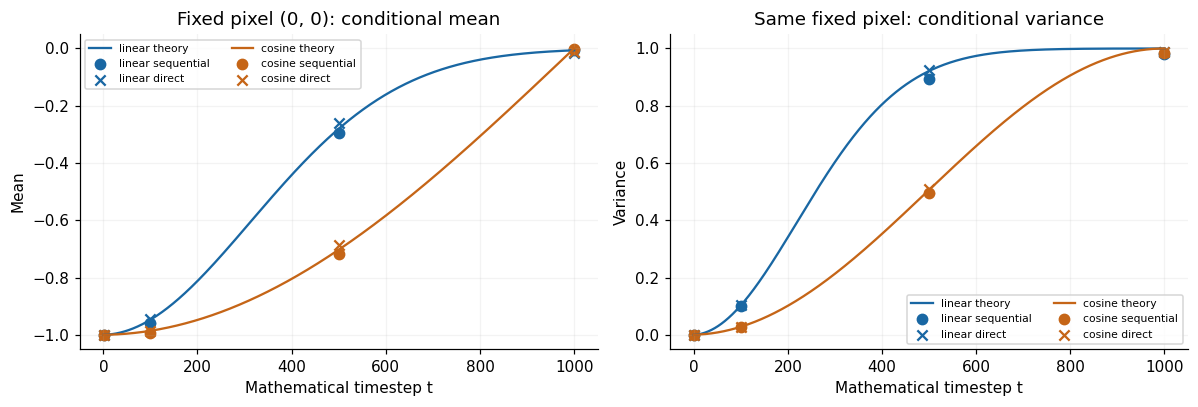

In [28]:
# Show the actual estimates for the first fixed coordinate.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for schedule_name, schedule in day5_schedules.items():
    color = day5_colors[schedule_name]
    ts = np.arange(config["T"] + 1)
    ab = schedule["alpha_bar"]
    axes[0].plot(ts, np.sqrt(ab) * fixed_point[0], color=color,
                 label=f"{schedule_name} theory")
    axes[1].plot(ts, 1.0 - ab, color=color, label=f"{schedule_name} theory")
    for method_name, marker in (("sequential", "o"), ("direct", "x")):
        rows = [
            r for r in day5_results
            if r["schedule"] == schedule_name and r["method"] == method_name
            and r["coordinate"] == 0
        ]
        axes[0].scatter([r["t"] for r in rows], [r["empirical_mean"] for r in rows],
                        color=color, marker=marker, s=45,
                        label=f"{schedule_name} {method_name}")
        axes[1].scatter([r["t"] for r in rows], [r["empirical_variance"] for r in rows],
                        color=color, marker=marker, s=45,
                        label=f"{schedule_name} {method_name}")
axes[0].set(title=f"Fixed pixel {fixed_locations[0]}: conditional mean", ylabel="Mean")
axes[1].set(title="Same fixed pixel: conditional variance", ylabel="Variance")
for ax in axes:
    ax.set_xlabel("Mathematical timestep t")
    ax.grid(alpha=0.15)
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day5_mc_moments.png", bbox_inches="tight")
plt.show()

## Day 5 · Observations for Discussion

Write one or two sentences per item using the output you actually obtained.

1. **Schedules:** At $t=500$, compare the signal amplitude, conditional
   variance, and recognizability under the two schedules. Why does the same
   timestep label not guarantee the same corruption level?
2. **Monte Carlo:** Pick one fixed coordinate, time, and schedule. Report
   the target mean/variance and the two methods' empirical estimates.
   Interpret the sampling discrepancies using $N$ and the error diagnostics.
3. **Evidence:** Explain what the checks support about the implementations.
   Would the schedule comparison establish which schedule generates better
   images after training?

### Your Day 5 observations — consolidated after discussion

**Discussion and final learner read-through completed on 2026-11-04.**

1. **Schedules:** At $t=500$, the linear images look unrecognizable to me, while the cosine images are very noisy but still retain some original patterns. The same timestep uses different cumulative products $\bar\alpha_t$ under the two schedules; here cosine gives a higher signal amplitude and lower noise amplitude.

| Schedule | Signal amplitude | Conditional variance | My observation at $t=500$ |
| --- | --- | --- | --- |
| Linear | 0.280334 | 0.921413 | Looks like noise; digits unrecognizable to me |
| Cosine | 0.702605 | 0.506346 | Very noisy; some original patterns recognizable |

2. **Monte Carlo:** I selected coordinate index 1, pixel $(5,18)$ of digit 0 with clean value $1$, at $t=100$ under the cosine schedule, using $N=4000$ repetitions per method. After comparing the mean discrepancies with their standard error of about $0.002659$, I found sequential about $0.20$ SE away and direct about $0.23$ SE away, both consistent with expected sampling variation.

| Quantity | Target | Sequential estimate | Direct estimate |
| --- | --- | --- | --- |
| Mean | 0.9857581658 | 0.9852260469 | 0.9863694586 |
| Variance | 0.0282808385 | 0.0274859649 | 0.0290450329 |

3. **Evidence:** The checks support that the sequential and direct implementations reproduce the predicted conditional moments within Monte Carlo error for the tested settings. They do not establish which schedule generates better images after training; this forward-only comparison shows more recognizable structure under this cosine schedule at $t=500$ in my selected images.


### Day 5 review — reasoning, corrections, and added explanations

My first schedule explanation and reported estimates were correct. I initially judged closeness by matching decimal places; after Codex supplied the standard error, I correctly interpreted both mean discrepancies relative to that scale. The direct result rounds to $0.23$ SE.

**Explanation added by Codex:** For these independent Gaussian repetitions, the estimator standard errors are

$$
\operatorname{SE}(\hat\mu)=\sqrt{\frac{v}{N}}\approx0.002659,
\qquad
\operatorname{SE}(\hat v)=v\sqrt{\frac{2}{N-1}}\approx0.00063246.
$$

| Method | Mean error / SE | Variance error / SE |
| --- | --- | --- |
| Sequential | -0.200 | -1.257 |
| Direct | +0.230 | +1.208 |

The variance estimates are about 1.26 and 1.21 of their own standard errors from the target, also consistent with sampling variation. An estimate need not fall within one SE. The six-SE threshold is a broad implementation diagnostic. Increasing $N$ improves expected precision without guaranteeing that every particular estimate gets closer.

**Interpretation clarified by Codex:** Sequential and direct are the sampling methods; linear and cosine are the schedules. The finite checks support the tested conditional moments and zero cross-covariance between the two coordinates, without establishing every distributional or trajectory property. The Day 3 derivation establishes the theoretical law. The observed recognizability difference concerns these schedules and images; no model was trained or reverse sampler evaluated.

**Code verification:** Both completed Day 5 exercises were correct. All 27 code cells passed a fresh execution on 2026-11-04, including all 16 schedule/method/time cases and 32 coordinate-level mean/variance pairs. Maximum absolute standardized errors across cases were 2.913 for means, 1.649 for variances, and 1.369 for cross-covariance, all below the six-SE tolerance. Diagnostic rows take maxima over both coordinates; the moment plot shows coordinate index 0, while my numerical example uses coordinate index 1.

See the [full Day 5 note and saved figures](../notes/w15_forward_process_discrete.md#day-5--comparing-schedules-and-checking-conditional-moments). Juan read and approved the cleaned note and notebook observations on 2026-11-04, completing Day 5.


## Day 5 Wrap-up

**Status:** Day 5 completed on 2026-11-04. The learner reviewed and approved the note, notebook observations, and review record.

**Stop here** once TODO 4 and TODO 5 pass their checks, the two schedules
have been compared using matched noise, and both sampling methods pass the
conditional moment and cross-covariance diagnostics. Bring the three
observations or any failed check for discussion.

**Common pitfalls:** comparing different clean pixels as if they were
repeated draws; estimating variance over the coordinate axis; using a
noise standard deviation as the variance target; clipping raw Monte Carlo
draws; requiring independent samples to match; using the ideal cosine curve
after changing its betas by clipping.

**Optional later:** change the number of draws from 4,000 to 100 and rerun
the Monte Carlo section. Explain what happens to the standard errors and
why a particular estimate need not improve monotonically with sample size.

**Run record:** root seed 15; Day 4 normalization and image selection;
recorded linear/cosine settings; fixed pixel coordinates; repetitions;
method-specific streams; and exported moment estimates. The working copy
retains the learner's completed code, saved outputs, consolidated
observations, and the review record above. Figures and the raw CSV are
saved under the ignored scratch directory; selected figures also appear
in the companion note.

**Day 6:** Completed on 2026-11-05. The final explanation, evidence discussion, learner questions, and completion record follow below.

# Day 6 — Consolidating the Forward Process and Closing Week 15

**Status:** Completed on 2026-11-05. Juan concluded his questions and
explicitly requested consolidation, Week 15 completion, and commit/push.
His opening explanation was explicitly without notes; the later discussion
reused saved evidence. Added explanations are identified below.

## My Forward-Process Explanation

The forward process starts from a clean dataset sample $x_0$ and corrupts
it through incremental Gaussian steps. Our chosen setup has $T=1000$:

$$
x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t,
\qquad \epsilon_t\sim\mathcal N(0,I).
$$

The schedule is fixed in advance. Each noise draw is fresh and independent
of the clean input and the other noise draws. Defining
$\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$ gives direct
sampling without simulating the intermediate states:

$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).
$$

I correctly recalled the resulting conditional law:

$$
q(x_t\mid x_0)=\mathcal N\!\left(
x_t;\sqrt{\bar\alpha_t}\,x_0,(1-\bar\alpha_t)I\right).
$$

**Notation supplied by Codex:** My opening omitted the explicit definition
$\alpha_t=1-\beta_t$. Codex also clarified that $\beta_t$ is the variance at
one step, while the sequence of these values is the schedule.

## Interpreting the Saved Evidence

I reused the Day 5 table. At $t=500$, cosine has a larger signal amplitude
and smaller conditional variance than linear:

| Schedule | Signal amplitude | Conditional variance |
| --- | --- | --- |
| Linear | 0.280334 | 0.921413 |
| Cosine | 0.702605 | 0.506346 |

That explains why I can recognize more of the selected digits under the
cosine schedule at this timestep. This observation concerns the saved
forward-corruption images.

For the cosine, coordinate-1, $t=100$ Monte Carlo example with $N=4000$, I
correctly described the estimator standard errors and standardized errors:

$$
\operatorname{SE}(\hat\mu)=\sqrt{v/N}\approx0.002659,
\qquad
\operatorname{SE}(\hat v)=v\sqrt{2/(N-1)}\approx0.00063246.
$$

Divide each absolute empirical-minus-target discrepancy by its estimator's
SE. The mean discrepancies are about 0.20 and 0.23 SE, and the variance
discrepancies about 1.26 and 1.21 SE. I interpreted these as consistent with
finite-sample variation. Codex clarified the wording: these SEs describe
variation of the estimators across repeated experiments. The targets and
estimates are preserved in the Day 5 numerical table above.

## Conditional Means and the Score

For an observed noisy image $X_t=x_t$, I would use
$\mathbb E[X_0\mid X_t=x_t]$ to estimate its clean source under squared
error. The observation is held fixed, and the average ranges over possible
clean sources using their posterior probabilities. In a discrete example,
sum clean value times posterior probability; use an integral for a density.

This differs from the forward mean
$\mathbb E[X_t\mid X_0=x_0]=\sqrt{\bar\alpha_t}\,x_0$, which holds the clean
input fixed and averages over corruption noise.

With the score formula included in the question, I correctly explained
that $\nabla_{x_t}\log q_t(x_t)$ gives a local direction of increasing
noisy-data log density. It describes a density gradient, while the clean
estimate is a posterior average of possible source images. Codex added
that the gradient gives the steepest local direction and its magnitude
gives the rate of increase in that direction.

**Small clarifications:** Codex wrote $X_t$ for a general timestep instead
of my $X_T$, and clarified the weighted-value wording. This naturally
revisited the [Week 14 conditioning/score discussion](../notes/w14_study_plan.md#day-7-completion-decision):
I distinguished the objects correctly in this context. An unaided
derivation of the identity relating the clean estimate to the score was
not assessed; that relationship remains part of Week 16's planned work.

## My Questions and the Added Explanations

**Cosine schedule: how much of its mathematics is needed now?**

I understood its implications and plots, but had only briefly inspected
the code. I asked whether a later exploration or blog post would be useful.

**Codex explanation:** Linear scheduling specifies the stepwise betas;
cosine scheduling first specifies a desired cumulative curve, then derives
the betas. For the desired curve $g_t=f(t)/f(0)$,

$$
f(t)=\cos^2\!\left(\frac{t/T+s}{1+s}\,\frac{\pi}{2}\right),
\qquad
\beta_t=1-\frac{g_t}{g_{t-1}}.
$$

The ratio follows from the cumulative-product recurrence. The notebook
clips the resulting betas and recomputes the actual cumulative product.
The authors chose cosine-squared for the desired decay shape and describe
other similarly shaped functions as possible alternatives; see
[Improved DDPM, Section 3.2](https://proceedings.mlr.press/v139/nichol21a/nichol21a.pdf#page=4).

Understanding the observed schedule effects meets this week's goal.
Tracing normalization, offset, and clipping is optional enrichment. A
possible later blog angle is "Why a linear noise schedule does not produce
linear signal decay." No post or additional study session was started.

**Percentages: can the squared coefficients describe a 90/10 split?**

Returning to the Day 4 percentage question, I correctly observed that
$a^2+b^2=1$ for $a=\sqrt{\bar\alpha_t}$ and
$b=\sqrt{1-\bar\alpha_t}$. I asked what percentage interpretation that
allows.

**Codex explanation:** For one coordinate across different clean inputs,
independence and unit noise variance give

$$
\operatorname{Var}(X_t)=a^2v_0+b^2,
\qquad v_0=\operatorname{Var}(X_0).
$$

If $v_0=1$, squared weights 0.9 and 0.1 are indeed 90% and 10% contributions
to the marginal variance. If $v_0=0.1$, the contributions are 0.09 and 0.1,
so noise contributes about 53% of the total variance. Normalizing the
pixel range does not ensure $v_0=1$. These are variance contributions,
not percentages of recognizable content or pixels. Given one fixed clean
input, the signal term is deterministic and the conditional variance is
$b^2$; the conditional mean still carries the scaled clean image.

**My alternative: what if the coefficients themselves sum to one?**

I proposed a different process with weights 0.99/0.01, then 0.98/0.02,
eventually 0.01/0.99. Treating the noise as fresh at every step gives, for
example,

$$
x_1=0.99x_0+0.01\epsilon_1,
\qquad
x_2=0.98x_1+0.02\epsilon_2.
$$

**Codex explanation:** This is a valid Gaussian noising process. Calling
the first step a 99% image / 1% noise blend describes its linear weights;
its noise variance contribution is $0.01^2=0.0001$. The second step blends
the already noisy $x_1$, so expansion gives

$$
x_2=0.9702x_0+0.0098\epsilon_1+0.02\epsilon_2.
$$

These linear weights sum to one. Independent noise variances still add
through squared weights. This family uses $a_t+b_t=1$, whereas our DDPM
uses $a_t^2+b_t^2=1$; changing only DDPM's beta cannot reproduce the exact
0.99/0.01 pair.

**Why does DDPM use the squared-coefficient constraint?**

I then asked what advantage it gives over my linear blend.

**Codex explanation and algebra:** With independent unit-variance inputs,
DDPM gives $(1-\beta_t)+\beta_t=1$ for the output variance. An equal linear
blend gives $0.5^2+0.5^2=0.5$. DDPM therefore keeps unit variance unchanged
as it replaces signal with noise. More generally, for a coordinate,

$$
\operatorname{Var}(X_t)
=\bar\alpha_t\operatorname{Var}(X_0)+(1-\bar\alpha_t).
$$

As the cumulative signal coefficient decreases, this marginal variance
moves toward one. An independent Gaussian step also leaves
$\mathcal N(0,I)$ unchanged if its input already has that law, giving a
convenient reference distribution for the endpoint and reverse sampler.
Sufficient cumulative attenuation is still needed to reach an approximately
standard-normal endpoint from image data. The original paper explicitly
discusses consistent network-input scale and matching the noise prior in
[DDPM, Appendix C](https://arxiv.org/pdf/2006.11239#page=15).

This is a convenient design, not evidence that every alternative blend
would generate worse images. I acknowledged the explanation and said my
questions were answered; independent recall of this added derivation was
not tested.

## Day 6 Review and Completion Decision

- My opening was explicitly notes-closed and correctly recalled both
  sampling equations, independence, and the conditional law. Codex supplied
  the omitted alpha definition and the schedule terminology.
- I used the saved schedule table to explain recognizability and correctly
  interpreted the Monte Carlo estimates using standard errors. These were
  prompted evidence discussions, not an additional blind recall test.
- I correctly distinguished posterior clean estimation from the score with
  the score formula supplied in the prompt. Codex refined notation and
  weighted-average wording; this is new positive evidence in the returning
  Week 14 context, not a claim that every related identity is fluent.
- My own questions produced the correct squared-weight identity and an
  alternative linear-blend proposal. The detailed cosine, variance-share,
  and variance-preserving explanations above were added by Codex. My
  acknowledgement after those explanations is not an independent test.

Juan explicitly requested closing Week 15 after the discussion. The
existing derivation, completed notebook, schedule comparison, numerical
checks, and final explanation meet the week's study scope. The new written
consolidation was prepared at that request; no separate post-writing
read-through is claimed. The optional Day 7 buffer can remain free.

## Handoff to Week 16

The working notebook retains the completed schedule, one-step and direct
samplers, normalization, seeded data setup, and conditional-moment checks.
These are the forward inputs for the next week. Compared with the
single-noise-level experiments in Weeks 1 and 8, we now have a consistent
family of indexed Gaussian corruption levels and their cumulative law.

Week 16 will add the training objective, timestep-conditioned noise
prediction, relationships among prediction parameterizations, and reverse
sampling. No denoiser or reverse sampler was trained or evaluated in Week
15. The [Week 16 curriculum](../CURRICULUM.md#week-16--first-full-toy-diffusion-training-small)
remains the next step; the optional cosine/blog exploration does not block it.